# Лабораторна робота №4: Класифікація видів ірисів

## Студент: ІСДМ-61, Мельник Ярослав Вікторович


---

### Мета роботи
Навчити модель машинного навчання визначати вид ірису (setosa, versicolor або virginica)
за чотирма вимірами: довжина та ширина чашолистка, довжина та ширина пелюстки.

### Завдання
1. Дослідити набір даних Iris
2. Розділити дані на навчальну та тестову вибірки
3. Побудувати модель k-найближчих сусідів
4. Оцінити якість моделі
5. **Дослідити вплив параметра `k` на точність** (власне дослідження)
6. Побудувати матрицю плутанини для детального аналізу помилок

In [3]:
# --- Базові бібліотеки ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Інструменти scikit-learn ---
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report

# --- Налаштування графіків ---
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Бібліотеки успішно завантажено")

Бібліотеки успішно завантажено


## I. Дослідження набору даних

Набір Iris — класичний приклад у машинному навчанні. Він містить 150 зразків,
по 50 на кожен із трьох видів. Розглянемо його структуру детальніше.

In [4]:
# Завантажуємо набір даних
iris = load_iris()

# Створюємо DataFrame для зручності аналізу
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target
df['species_name'] = df['species'].map(dict(enumerate(iris.target_names)))

print("Загальна інформація про набір:")
print(f" Кількість зразків: {df.shape[0]}")
print(f" Кількість ознак: {df.shape[1] - 2}")
print(f" Класи: {list(iris.target_names)}")
print()
print("Перші 5 рядків таблиці:")
df.head()

Загальна інформація про набір:
 Кількість зразків: 150
 Кількість ознак: 4
 Класи: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Перші 5 рядків таблиці:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [6]:
# Описова статистика за видами
print("Середні значення ознак за видами:")
df.groupby('species_name')[iris.feature_names].mean().round(2)

Середні значення ознак за видами:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species_name,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


Розподіл зразків за класами:
species_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


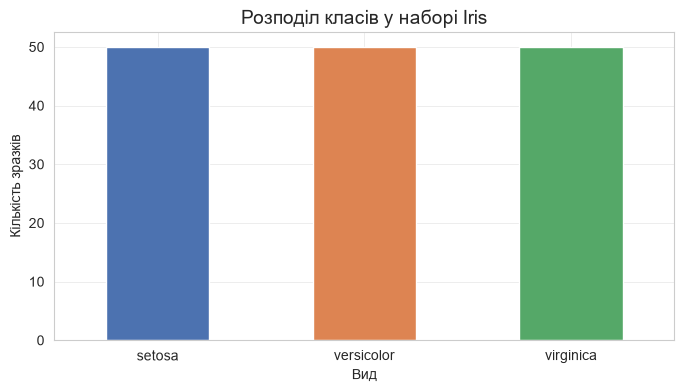

In [7]:
# Перевіряємо, чи збалансований набір
class_counts = df['species_name'].value_counts()
print("Розподіл зразків за класами:")
print(class_counts)

# Візуалізація
plt.figure(figsize=(8, 4))
class_counts.plot(kind='bar', color=['#4C72B0', '#DD8452', '#55A868'])
plt.title("Розподіл класів у наборі Iris", fontsize=14)
plt.xlabel("Вид")
plt.ylabel("Кількість зразків")
plt.xticks(rotation=0)
plt.show()

## II. Візуальний аналіз даних

Побудуємо матрицю діаграм розсіювання — вона допоможе побачити,
наскільки добре види відокремлені один від одного.

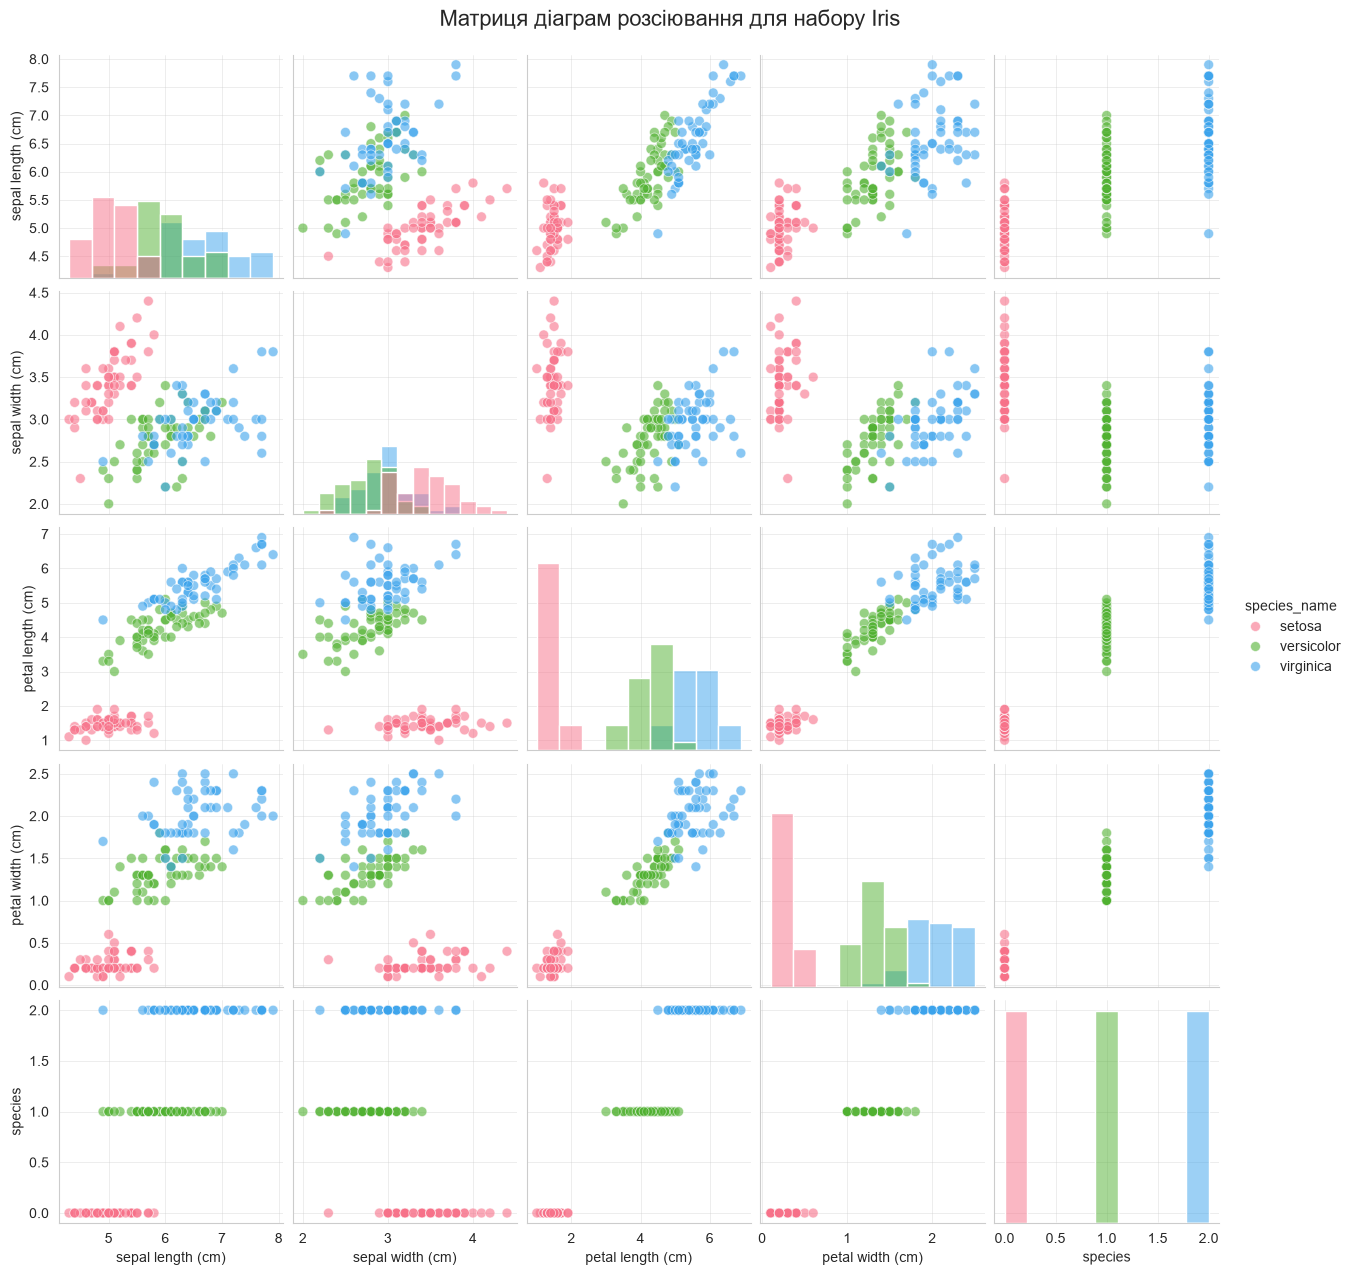

In [8]:
# Побудова матриці діаграм розсіювання з seaborn (виглядає краще, ніж pandas)
sns.pairplot(
    df,
    hue='species_name',
    palette='husl',
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 50}
)
plt.suptitle("Матриця діаграм розсіювання для набору Iris", y=1.02, fontsize=16)
plt.show()


З діаграм видно, що:
- **Setosa** чітко відокремлена від двох інших видів (особливо за пелюстковими ознаками).
- **Versicolor** та **Virginica** частково перетинаються, але все ще достатньо розрізняються.
- Найкращі ознаки для розділення: **довжина та ширина пелюстки**.

Отже, навіть простий алгоритм має впоратися з цим завданням.

## III. Розділення даних

Використовуємо стандартне співвідношення 75/25. Фіксуємо `random_state=42`,
щоб результат був відтворюваним.

In [9]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Тренувальна вибірка: {X_train.shape[0]} зразків")
print(f"Тестова вибірка:     {X_test.shape[0]} зразків")
print()
print("Перевірка балансу в обох вибірках:")
print(f"  Train: {np.bincount(y_train)}")
print(f"  Test:  {np.bincount(y_test)}")

Тренувальна вибірка: 112 зразків
Тестова вибірка:     38 зразків

Перевірка балансу в обох вибірках:
  Train: [38 37 37]
  Test:  [12 13 13]


## IV. Побудова моделі k-NN

Створимо базову модель з `k=1` та навчимо її.

In [10]:
# Створюємо та тренуємо класифікатор
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

print("Модель навчено!")
print(f"Алгоритм: k-NN з k=1")

Модель навчено!
Алгоритм: k-NN з k=1


## V. Прогнозування для нової квітки

Уявімо, що ми знайшли квітку з такими вимірами:
- Довжина чашолистка: 5.0 см
- Ширина чашолистка: 2.9 см
- Довжина пелюстки: 1.0 см
- Ширина пелюстки: 0.2 см



In [11]:
# Новий зразок
new_flower = np.array([[5.0, 2.9, 1.0, 0.2]])

# Прогноз
prediction = knn.predict(new_flower)
probabilities = knn.predict_proba(new_flower)[0]

print("Результат прогнозу:")
print(f"   Передбачений вид: {iris.target_names[prediction[0]]}")
print()
print("Ймовірності по класах:")
for name, prob in zip(iris.target_names, probabilities):
    print(f"   {name:12s}: {prob:.2%}")

Результат прогнозу:
   Передбачений вид: setosa

Ймовірності по класах:
   setosa      : 100.00%
   versicolor  : 0.00%
   virginica   : 0.00%


## VI. Оцінка якості базової моделі

Перевіримо, наскільки добре модель працює на тестовій вибірці.

In [12]:
# Прогнози для тестової вибірки
y_pred = knn.predict(X_test)

# Точність
accuracy = knn.score(X_test, y_test)
print(f"Точність моделі (k=1): {accuracy:.4f} ({accuracy*100:.2f}%)")

# Детальний звіт
print("\nДетальний звіт по класах:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Точність моделі (k=1): 0.9474 (94.74%)

Детальний звіт по класах:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.87      1.00      0.93        13
   virginica       1.00      0.85      0.92        13

    accuracy                           0.95        38
   macro avg       0.96      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



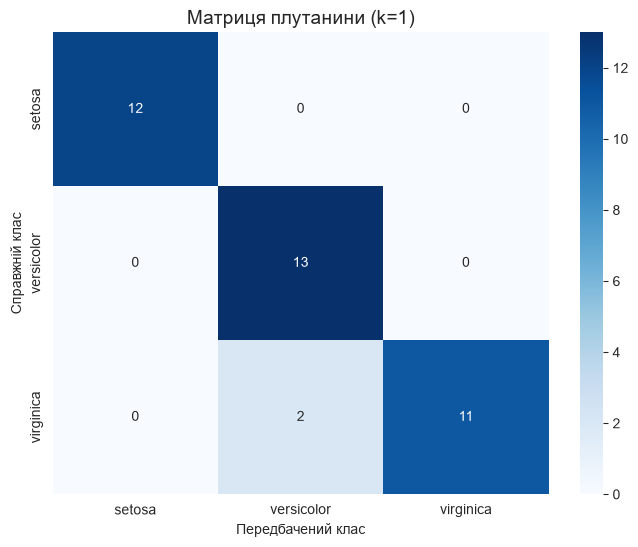

In [13]:
# Побудова матриці плутанини
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.title("Матриця плутанини (k=1)", fontsize=14)
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.show()

### Що показує матриця плутанини?

По діагоналі — правильно класифіковані зразки. Поза діагоналлю — помилки.

Якщо є значення поза діагоналлю, це означає, що модель плутає певні види.
Зазвичай, якщо помилки й є, то між versicolor та virginica.

## VII. Власне дослідження: вплив параметра `k`

У прикладі з підручника використовується `k=1`. Перевіримо що буде якщо діапазон від 1 до 15.

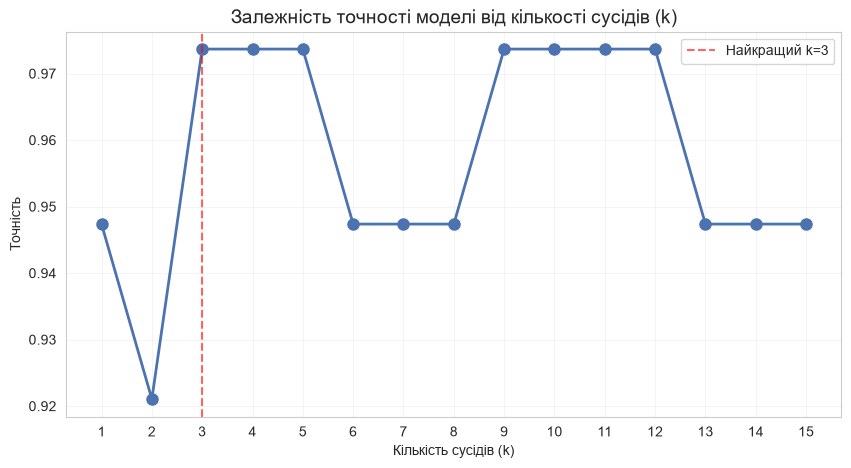

Найкращий результат: k=3, точність = 0.9737


In [14]:
# Перебираємо значення k від 1 до 15
k_values = range(1, 16)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    accuracies.append(acc)

# Візуалізація
plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='#4C72B0', linewidth=2, markersize=8)
plt.title("Залежність точності моделі від кількості сусідів (k)", fontsize=14)
plt.xlabel("Кількість сусідів (k)")
plt.ylabel("Точність")
plt.grid(True, alpha=0.3)
plt.xticks(k_values)

# Позначаємо найкращий k
best_k = k_values[int(np.argmax(accuracies))]
best_acc = max(accuracies)
plt.axvline(best_k, color='red', linestyle='--', alpha=0.6, label=f'Найкращий k={best_k}')
plt.legend()
plt.show()

print(f"Найкращий результат: k={best_k}, точність = {best_acc:.4f}")

### 💡 Висновок

- Точність залежить від `k` нелінійно — є як зростання, так і провали.
- **Найгірший результат — `k=2`** (~0.92).
- **Найкращий результат — `k=3`** (97.4%). Далі точність тримається на плато для `k=4, 5, 9, 10, 11, 12`.
- Отже, `k=3` — оптимальний вибір: максимальна точність при мінімальній складності.

## Загальний висновок

У роботі ми:
1. Дослідили набір Iris та переконалися, що класи добре розділювані.
2. Розділили дані на train/test зі збереженням пропорцій класів.
3. Побудували модель k-NN та оцінили її точність.
4. Дослідили вплив параметра `k` — найкращий результат при `k=3` (97.4%).

**Головне:** навіть простий алгоритм k-NN дає високу точність на цьому наборі. Правильний підбір `k` дозволяє покращити результат порівняно з базовим `k=1`.
